# Práctica Clase 9: Árboles de Decisión y Ensambles
En esta clase exploraremos los árboles de decisión basándonos en los conceptos teóricos de *Information Gain* y *Gini Impurity*. Luego, abordaremos el problema del sobreajuste (overfitting) mediante técnicas de poda (pruning).

Finalmente, daremos el salto a los métodos de ensamble, comparando **Random Forest**, **XGBoost** y **LightGBM**, y aprenderemos a optimizar sus hiperparámetros usando **Optuna**.

## 0. Instalación e Importaciones
Primero, importamos todas las librerías necesarias. Si no cuentas con `xgboost`, `lightgbm` u `optuna`, asegúrate de instalarlas.

In [1]:
# !pip install xgboost lightgbm optuna

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_breast_cancer, make_moons

import xgboost as xgb
import lightgbm as lgb
import optuna

# Configuración visual global
plt.rcParams.update({'figure.figsize': (10, 6), 'axes.grid': True, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Árboles de Decisión: Ejemplo Teórico (vous vs tu)
De acuerdo al Capítulo 8 de los apuntes teóricos, un árbol divide los datos para maximizar la **Ganancia de Información** (reduciendo la Entropía).

Construiremos el dataset de juguete de la clase: predecir si en francés usamos 'vous' o 'tu' basados en `Age`, `Friend` y `Gender`.

In [3]:
# Dataset de juguete (Age: 1=Adult, 0=Child | Friend: 1=Yes, 0=No | Gender: 1=M, 0=F)
data = {
    'Age': [1, 1, 1, 1, 0],
    'Friend': [0, 0, 1, 1, 0],
    'Gender': [1, 0, 1, 0, 1],
    'Target': [1, 1, 0, 0, 0]  # 1 = vous, 0 = tu
}
df_toy = pd.DataFrame(data)
display(df_toy)

X_toy = df_toy[['Age', 'Friend', 'Gender']]
y_toy = df_toy['Target']

,Age,Friend,Gender,Target
0,1,0,1,1
1,1,0,0,1
2,1,1,1,0
3,1,1,0,0
4,0,0,1,0


### Visualización rápida del Dataset
Veamos la distribución de nuestra variable objetivo 'Target' respecto a la característica 'Friend'.

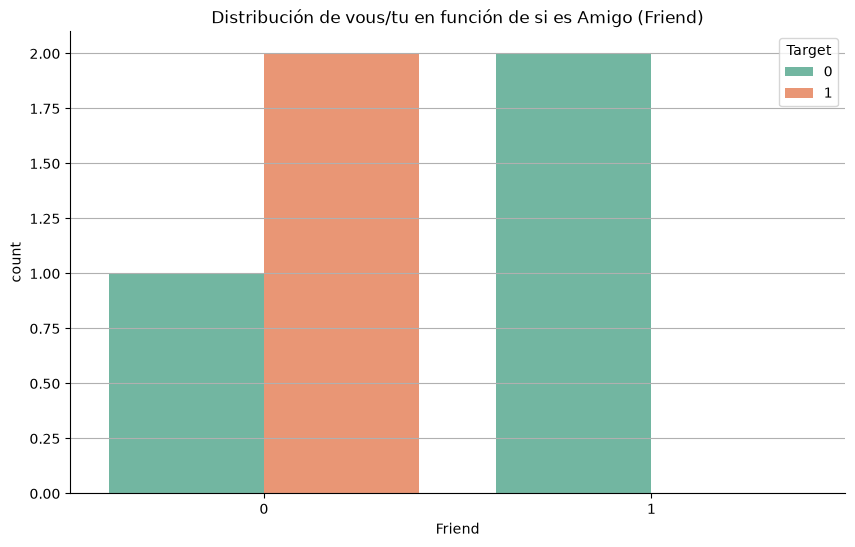

In [4]:
sns.countplot(data=df_toy, x='Friend', hue='Target', palette='Set2')
plt.title('Distribución de vous/tu en función de si es Amigo (Friend)')
plt.show()

### Entrenamiento del Modelo
Vamos a instanciar y entrenar un `DecisionTreeClassifier` utilizando la entropía como criterio de división.

In [5]:
tree_toy = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
tree_toy.fit(X_toy, y_toy)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

### Gráfico del Árbol de Decisión
Visualicemos las reglas aprendidas por el modelo. Podrás notar que el primer corte ocurre en la característica `Friend`, tal como predecía la teoría.

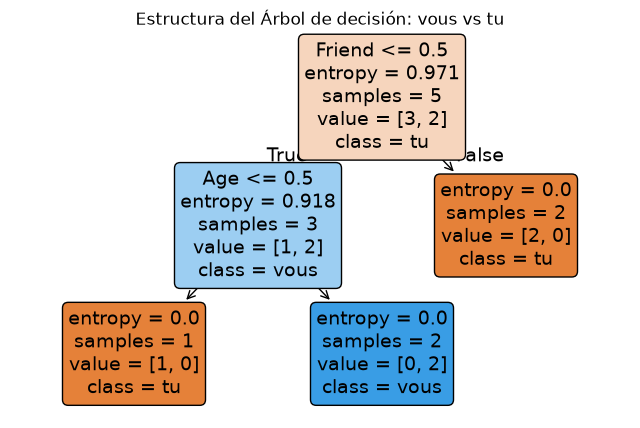

In [6]:
plt.figure(figsize=(8, 5))
plot_tree(tree_toy, feature_names=list(X_toy.columns), class_names=['tu', 'vous'], filled=True, rounded=True)
plt.title("Estructura del Árbol de decisión: vous vs tu")
plt.show()

## 2. Feature Importance
El árbol puede indicarnos qué característica fue la más útil para clasificar. La característica de mayor importancia será aquella que haya reducido más la impureza global.

In [7]:
importances = tree_toy.feature_importances_
features = X_toy.columns

Grafiquemos esta importancia para interpretar el modelo.

C:\Users\Carlos Benitez\AppData\Local\Temp\ipykernel_26520\453322697.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=list(features), palette='viridis')


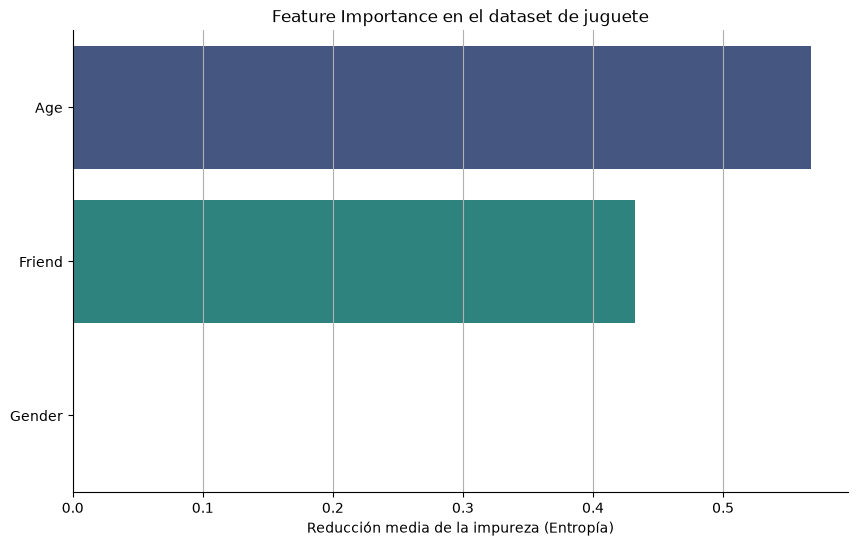

In [8]:
sns.barplot(x=importances, y=list(features), palette='viridis')
plt.title('Feature Importance en el dataset de juguete')
plt.xlabel('Reducción media de la impureza (Entropía)')
plt.show()

## 3. Poda (Pruning) para evitar Overfitting
Los árboles son propensos a memorizar el ruido (sobreajuste). Para demostrarlo, generaremos un dataset ruidoso en forma de dos medias lunas (`make_moons`).

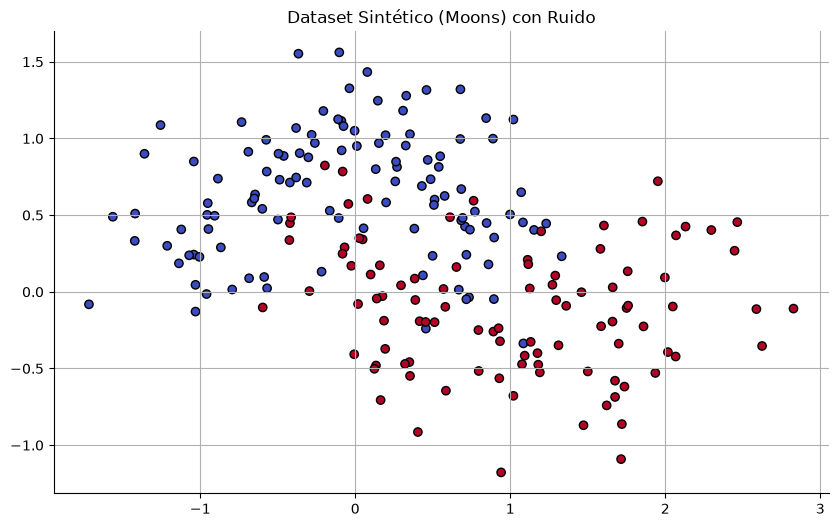

In [9]:
# Generamos un dataset sintético ruidoso
X_moons, y_moons = make_moons(n_samples=300, noise=0.3, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X_moons, y_moons, test_size=0.3, random_state=42)

plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', edgecolors='k')
plt.title('Dataset Sintético (Moons) con Ruido')
plt.show()

### El problema del Árbol Profundo (Sin Poda)
Entrenaremos un árbol sin limitar su profundidad. Esto generará fronteras de decisión extremadamente complejas.

In [10]:
def plot_decision_boundary(clf, X, y, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap='coolwarm')
    plt.title(title)

tree_overfit = DecisionTreeClassifier(random_state=42)
tree_overfit.fit(X_train, y_train)
acc_train_over = accuracy_score(y_train, tree_overfit.predict(X_train))
acc_test_over = accuracy_score(y_test, tree_overfit.predict(X_test))

### Árbol con Pre-pruning (Poda Preventiva)
Ahora entrenaremos un árbol con `max_depth=4` y `min_samples_leaf=5`, lo cual fuerza al árbol a generalizar.

In [11]:
tree_pruned = DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42)
tree_pruned.fit(X_train, y_train)
acc_train_prune = accuracy_score(y_train, tree_pruned.predict(X_train))
acc_test_prune = accuracy_score(y_test, tree_pruned.predict(X_test))

### Comparación Visual de las Fronteras
Observemos cómo la poda simplifica enormemente las regiones de decisión.

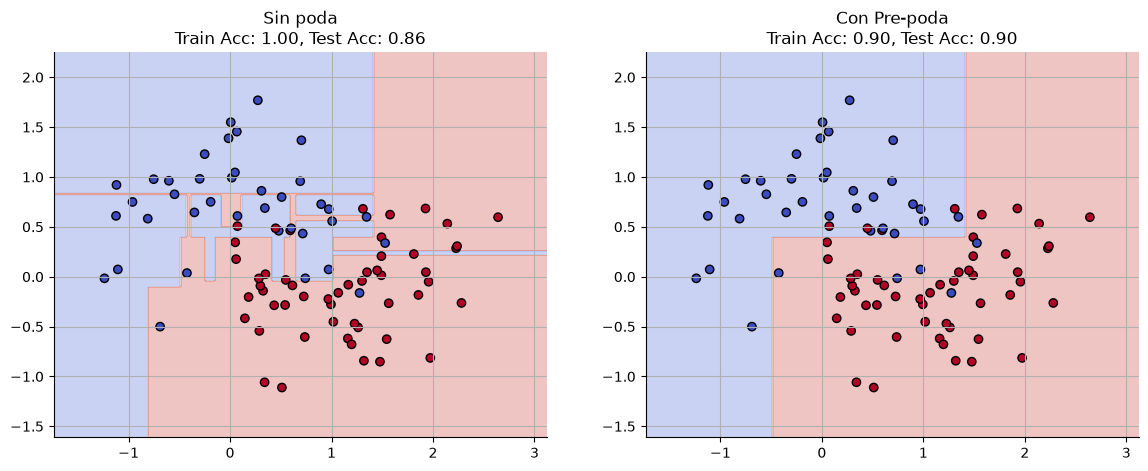

In [12]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plot_decision_boundary(tree_overfit, X_test, y_test, f'Sin poda\nTrain Acc: {acc_train_over:.2f}, Test Acc: {acc_test_over:.2f}')
plt.subplot(1, 2, 2)
plot_decision_boundary(tree_pruned, X_test, y_test, f'Con Pre-poda\nTrain Acc: {acc_train_prune:.2f}, Test Acc: {acc_test_prune:.2f}')
plt.show()

## 4. Comparación de Ensambles: Random Forest, XGBoost, LightGBM
Para reducir la varianza y mejorar el desempeño, se utilizan ensambles de múltiples árboles. Emplearemos el dataset de Cáncer de Mama para comparar algoritmos.

In [13]:
cancer = load_breast_cancer()
X_bc, y_bc = cancer.data, cancer.target
X_train_bc, X_test_bc, y_train_bc, y_test_bc = train_test_split(X_bc, y_bc, test_size=0.25, random_state=42)

### Entrenamiento y Medición de Tiempo
Entrenaremos los tres modelos estrella. XGBoost y LightGBM son implementaciones ultra rápidas basadas en *Gradient Boosting*.

In [14]:
from time import time

models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'XGBoost': xgb.XGBClassifier(n_estimators=100, eval_metric='logloss', random_state=42),
    'LightGBM': lgb.LGBMClassifier(n_estimators=100, random_state=42, verbose=-1)
}

results = []
for name, model in models.items():
    t0 = time()
    model.fit(X_train_bc, y_train_bc)
    t_fit = time() - t0
    
    y_pred = model.predict(X_test_bc)
    acc = accuracy_score(y_test_bc, y_pred)
    
    results.append({'Modelo': name, 'Accuracy Test': acc, 'Tiempo (s)': t_fit})

df_results = pd.DataFrame(results)
display(df_results)

,Modelo,Accuracy Test,Tiempo (s)
0,Random Forest,0.965035,0.577062
1,XGBoost,0.965035,0.347189
2,LightGBM,0.951049,14.931559


### Gráfica de Desempeño y Velocidad
Comparemos visualmente la Precisión y el Tiempo que tomó entrenarlos.

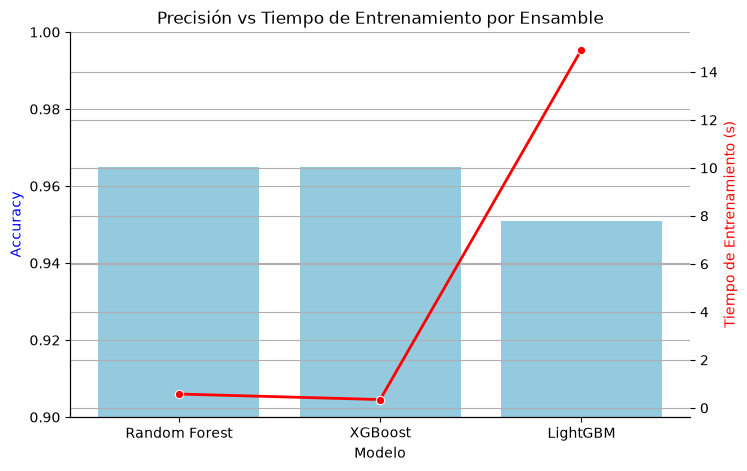

In [15]:
fig, ax1 = plt.subplots(figsize=(8, 5))

sns.barplot(data=df_results, x='Modelo', y='Accuracy Test', ax=ax1, color='skyblue')
ax1.set_ylim(0.9, 1.0)
ax1.set_ylabel('Accuracy', color='blue')

ax2 = ax1.twinx()
sns.lineplot(data=df_results, x='Modelo', y='Tiempo (s)', ax=ax2, color='red', marker='o', linewidth=2)
ax2.set_ylabel('Tiempo de Entrenamiento (s)', color='red')

plt.title('Precisión vs Tiempo de Entrenamiento por Ensamble')
plt.show()

## 5. Optimización de Hiperparámetros con Optuna
Finalmente, usaremos **Optuna** para encontrar los parámetros óptimos de nuestro modelo LightGBM. Primero, definimos la **función objetivo**.

In [16]:
def objective(trial):
    param = {
        'objective': 'binary',
        'metric': 'binary_logloss',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'random_state': 42,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=10),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 30),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0)
    }
    
    # Usamos validación cruzada para medir la calidad del hiperparámetro
    model = lgb.LGBMClassifier(**param)
    score = cross_val_score(model, X_train_bc, y_train_bc, cv=3, scoring='accuracy').mean()
    
    return score

### Ejecución del Estudio
Creamos el estudio indicando que deseamos *maximizar* la métrica (Accuracy) y le asignamos 20 pruebas (trials).

In [17]:
study = optuna.create_study(direction='maximize')
optuna.logging.set_verbosity(optuna.logging.WARNING) # Evitar exceso de logs
study.optimize(objective, n_trials=20)

print("Mejores hiperparámetros encontrados:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")
print(f"\nMejor Accuracy Validación Cruzada: {study.best_value:.4f}")

[I 2026-10-11 06:05:50,566] A new study created in memory with name: no-name-905f2af6-a380-4346-98a2-aab6646c6aca


Mejores hiperparámetros encontrados:
  learning_rate: 0.13376203388063204
  num_leaves: 60
  max_depth: 4
  min_child_samples: 8
  subsample: 0.8658604320652546

Mejor Accuracy Validación Cruzada: 0.9648


### Historial de Optimización
Optuna nos permite graficar fácilmente cómo fue aprendiendo y mejorando la elección de parámetros con cada iteración.

C:\Users\Carlos Benitez\AppData\Local\Temp\ipykernel_26520\3519348612.py:4: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study)


<Figure size 1000x600 with 0 Axes>

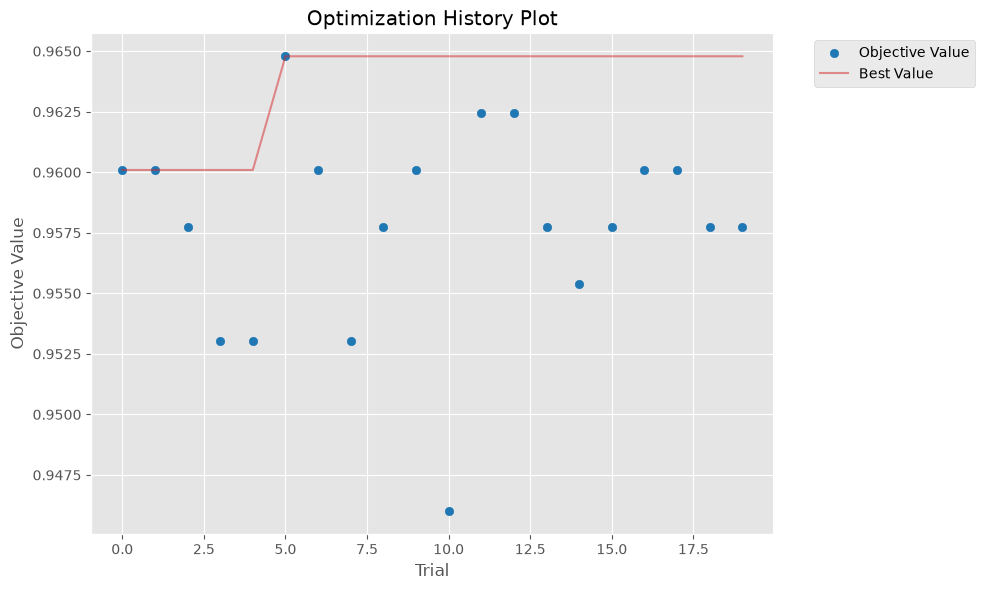

In [18]:
from optuna.visualization.matplotlib import plot_optimization_history

plt.figure(figsize=(10, 6))
plot_optimization_history(study)
plt.tight_layout()
plt.show()